# heading 

First, the data needs to be prepared. The geometries and their alignments are extracted from the json and geojson files, the scale of each map object is calculated, and the results are stored in a geodataframe per sketch map.

In [58]:
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import json
from shapely.geometry import shape, MultiPolygon, MultiLineString, MultiPoint
import os

In [63]:
# input: an alignment.json file, a sketchmap.geojson and the according basemap.geojson from a SketchMapia project, and the name of the sketch map
# output: a geodataframe with one row per sketch map object and a column for their scales relative to their basemap equivalent

def calculate_scales(alignment_file, basemap_geojson, sketchmap_geojson, sketch_map_name):
    
    # create empty list
    alignment_list = []
    
    # iterate over the sketchmaps in the alignment json file
    for map_name, sketchmap in alignment_file.items():
        # iterate over the alignments of each sketchmap
        for alignment_id, alignment in sketchmap.items():
            # skip metadata and find only the specified sketch map
            if alignment_id == "checkAlignnum" or map_name != sketch_map_name:
                continue
            #print(map_name)
            sid_list = alignment['SketchAlign']['0']
            sketch_feat_type = None
            sketch_geom = []
            base_feat_type = None
            base_geom = []
            for sid in sid_list: # there may be one or multiple sketchmap objects in each alignment
                for feature in sketchmap_geojson['features']: # find the object referenced by the sid in the sketchmap geojson
                    if feature['properties']['sid'] == sid:
                        sketch_feat_type = (feature['geometry']['type']) # knowing that if there are multiple objects, they will be of the same type
                        sketch_geom.append(feature['geometry'])
                base_ids = alignment['BaseAlign']['0']
                for base_feature in basemap_geojson['features']: # find the basemap equivalent
                    if base_feature['properties'].get('id') in base_ids:
                        base_feat_type = (base_feature['geometry']['type']) # knowing that if there are multiple objects, they will be of the same type
                        base_geom.append(base_feature['geometry'])
            alignment_list.append([map_name, sketch_feat_type, sketch_geom, base_feat_type, base_geom])
    table = pd.DataFrame(alignment_list)
    table.columns = ['Map_name', 'Sketch_map_feature_type', 'Sketch_map_geometry', 'Base_map_feature_type', 'Base_map_geometry']
    #print(table.head())
    
    # calculate size columns (length (for linestrings) / area (for polygons); points can be ignored since they don't have a size)

    sketch_sizes = []
    base_sizes = []
    
    for row in table.itertuples():
        
        # sketch map:
        
        if row.Sketch_map_feature_type == 'LineString':
            # calculate length
            ls = row.Sketch_map_geometry
            geom = [shape(item) for item in ls]
            gs = gpd.GeoSeries(geom)
            sketch_sizes.append(gs.length[0])
        else:
            if row.Sketch_map_feature_type == 'Polygon':
                # calculate area
                a = row.Sketch_map_geometry
                geom = [shape(item) for item in a]
                gs = gpd.GeoSeries(geom)
                sketch_sizes.append(gs.area[0])
            else:
                sketch_sizes.append(None)

        # base map:
        
        if row.Base_map_feature_type == 'LineString':
            # calculate length
            ls = row.Base_map_geometry
            geom = [shape(item) for item in ls]
            gs = gpd.GeoSeries(geom)
            base_sizes.append(gs.length[0])
        else: 
            if row.Base_map_feature_type == 'Polygon':
                # calculate area
                a = row.Base_map_geometry
                geom = [shape(item) for item in a]
                gs = gpd.GeoSeries(geom)
                base_sizes.append(gs.area[0])
            else:
                base_sizes.append(None)
                
    # append to table
    table.insert(5, 'Sketch_size', sketch_sizes)
    table.insert(6, 'Basemap_size', base_sizes)

    # calculate scales

    scale = []
    
    for row in table.itertuples():
        if row.Sketch_size == None or row.Basemap_size == None:
            s = None
        else:
            s = row.Basemap_size / row.Sketch_size
        scale.append(s)
    
    table.insert(7, 'Scale', scale)

    # to create the geodataframe, the geometries must be converted to valid pandas geometries
    
    sketch_geom = []
    base_geom = []
    
    for row in table.itertuples():
        
        # convert every sketch map geometry to shapely geometry and collect them in a list
        if row.Sketch_map_geometry == None or row.Sketch_map_feature_type == None:
            sg = None
        if len(row.Sketch_map_geometry) == 1:
            sg = (shape(row.Sketch_map_geometry[0]))
        else:
            sg_list = []
            sg_list = [shape(geom) for geom in row.Sketch_map_geometry]
            if row.Sketch_map_feature_type == 'Polygon':
                sg = MultiPolygon(sg_list)
            else:
                if row.Sketch_map_feature_type == 'LineString':
                    sg = MultiLineString(sg_list)
                else:
                    if row.Sketch_map_feature_type == 'Point':
                        sg = MultiPoint(sg_list)
        sketch_geom.append(sg)
    
        # convert every base map geometry to shapely geometry and collect them in a list
        if row.Base_map_geometry == None:
            bg = None
        if len(row.Base_map_geometry) == 1:
            bg = (shape(row.Base_map_geometry[0]))
        else:
            bg_list = []
            bg_list = [shape(geom) for geom in row.Base_map_geometry]
            if row.Base_map_feature_type == 'Polygon':
                bg = MultiPolygon(bg_list)
            else:
                if row.Base_map_feature_type == 'LineString':
                    bg = MultiLineString(bg_list)
                else: bg = None
        base_geom.append(bg)
    
    # append the shapely geometries as new columns to the table
    table.insert(8, 'Pandas_sketch_geometry', sketch_geom)
    table.insert(9, 'Pandas_base_geometry', base_geom)
    
    #print(table.head())

    # create geodataframe
    gdf = gpd.GeoDataFrame(table, geometry = table.Pandas_sketch_geometry)
    return gdf

In [24]:
with open("Route_Hbf_Dom\\InputFiles(16)\\alignment.json") as data_a, open("Route_Hbf_Dom\\InputFiles(16)\\Screenshot 2026-10-06 143753.png.geojson") as data_b, open("Route_Hbf_Dom\\InputFiles(16)\\02_Route1.jpg.geojson") as data_s:
    alignment_file = json.load(data_a)
    basemap_geojson = json.load(data_b)
    sketchmap_geojson = json.load(data_s)
    sketch_map_name = "02_Route1.jpg"

    gdf = calculate_scales(alignment_file, basemap_geojson, sketchmap_geojson, sketch_map_name)

    print(gdf.head())

        Map_name Sketch_map_feature_type  \
0  02_Route1.jpg                 Polygon   
1  02_Route1.jpg                 Polygon   
2  02_Route1.jpg              LineString   
3  02_Route1.jpg              LineString   
4  02_Route1.jpg              LineString   

                                 Sketch_map_geometry Base_map_feature_type  \
0  [{'type': 'Polygon', 'coordinates': [[[257.25,...               Polygon   
1  [{'type': 'Polygon', 'coordinates': [[[544, 13...               Polygon   
2  [{'type': 'LineString', 'coordinates': [[0, 46...            LineString   
3  [{'type': 'LineString', 'coordinates': [[336.8...            LineString   
4  [{'type': 'LineString', 'coordinates': [[336.8...            LineString   

                                   Base_map_geometry   Sketch_size  \
0  [{'type': 'Polygon', 'coordinates': [[[651.25,...   7292.761310   
1  [{'type': 'Polygon', 'coordinates': [[[366.187...  12100.413408   
2  [{'type': 'LineString', 'coordinates': [[630.0...    

In [ ]:
map_name = sketch_map_name.replace('.', '_') # remove points from the table name
    name = "gdf_" +  map_name
    exec(f"{name} = {gpd.GeoDataFrame(table, geometry = table.Pandas_sketch_geometry)}")
    #gdf = gpd.GeoDataFrame(table, geometry = table.Pandas_sketch_geometry)

In [25]:
with open("Osaka\\alignment.json") as data_a, open("Osaka\\osakametro_rosenzu_20250404.jpg.geojson") as data_s, open("Osaka\\Wide-Area_Map_of_Osaka_City_Subway.png.geojson") as data_b:
    alignment_file = json.load(data_a)
    basemap_geojson = json.load(data_b)
    sketchmap_geojson = json.load(data_s)
    sketch_map_name = "osakametro_rosenzu_20250404.jpg"

    gdf_osaka = calculate_scales(alignment_file, basemap_geojson, sketchmap_geojson, sketch_map_name)

    print(gdf_osaka.head())

                          Map_name Sketch_map_feature_type  \
0  osakametro_rosenzu_20250404.jpg              LineString   
1  osakametro_rosenzu_20250404.jpg              LineString   
2  osakametro_rosenzu_20250404.jpg              LineString   
3  osakametro_rosenzu_20250404.jpg              LineString   
4  osakametro_rosenzu_20250404.jpg              LineString   

                                 Sketch_map_geometry Base_map_feature_type  \
0  [{'type': 'LineString', 'coordinates': [[514.2...            LineString   
1  [{'type': 'LineString', 'coordinates': [[513.5...            LineString   
2  [{'type': 'LineString', 'coordinates': [[513.5...            LineString   
3  [{'type': 'LineString', 'coordinates': [[513.5...            LineString   
4  [{'type': 'LineString', 'coordinates': [[513.5...            LineString   

                                   Base_map_geometry  Sketch_size  \
0  [{'type': 'LineString', 'coordinates': [[307.2...    16.265654   
1  [{'type': 'LineSt

In [78]:
with open("Nürnberg\\alignment.json") as data_a, open("Nürnberg\\u-bahn-liniennetz.jpg.geojson") as data_s, open("Nürnberg\\u-bahnnetz_stand_2026.jpg.geojson") as data_b:
    alignment_file = json.load(data_a)
    basemap_geojson = json.load(data_b)
    sketchmap_geojson = json.load(data_s)
    sketch_map_name = "u-bahn-liniennetz.jpg"

    gdf_nuremberg = calculate_scales(alignment_file, basemap_geojson, sketchmap_geojson, sketch_map_name)

    print(gdf_nuremberg.head())

                Map_name Sketch_map_feature_type  \
0  u-bahn-liniennetz.jpg              LineString   
1  u-bahn-liniennetz.jpg              LineString   
2  u-bahn-liniennetz.jpg              LineString   
3  u-bahn-liniennetz.jpg              LineString   
4  u-bahn-liniennetz.jpg              LineString   

                                 Sketch_map_geometry Base_map_feature_type  \
0  [{'type': 'LineString', 'coordinates': [[811.7...            LineString   
1  [{'type': 'LineString', 'coordinates': [[782.1...            LineString   
2  [{'type': 'LineString', 'coordinates': [[782.1...            LineString   
3  [{'type': 'LineString', 'coordinates': [[753.2...            LineString   
4  [{'type': 'LineString', 'coordinates': [[753.2...            LineString   

                                   Base_map_geometry  Sketch_size  \
0  [{'type': 'LineString', 'coordinates': [[818.7...    29.625890   
1  [{'type': 'LineString', 'coordinates': [[796.2...     7.939011   
2  [{'type'

In [50]:
with open("Hamburg\\alignment.json") as data_a, open("Hamburg\\hvv_usar-plan.jpg.geojson") as data_s, open("Hamburg\\Topografischer_Netzplan_U-Bahn_Hamburg.png.geojson") as data_b:
    alignment_file = json.load(data_a)
    basemap_geojson = json.load(data_b)
    sketchmap_geojson = json.load(data_s)
    sketch_map_name = "hvv_usar-plan.jpg"

    gdf_hamburg = calculate_scales(alignment_file, basemap_geojson, sketchmap_geojson, sketch_map_name)

    print(gdf_hamburg.head())

            Map_name Sketch_map_feature_type  \
0  hvv_usar-plan.jpg              LineString   
1  hvv_usar-plan.jpg              LineString   
2  hvv_usar-plan.jpg              LineString   
3  hvv_usar-plan.jpg              LineString   
4  hvv_usar-plan.jpg              LineString   

                                 Sketch_map_geometry Base_map_feature_type  \
0  [{'type': 'LineString', 'coordinates': [[701.9...            LineString   
1  [{'type': 'LineString', 'coordinates': [[686.1...            LineString   
2  [{'type': 'LineString', 'coordinates': [[686.1...            LineString   
3  [{'type': 'LineString', 'coordinates': [[671.1...            LineString   
4  [{'type': 'LineString', 'coordinates': [[671.1...            LineString   

                                   Base_map_geometry  Sketch_size  \
0  [{'type': 'LineString', 'coordinates': [[570.5...    15.750124   
1  [{'type': 'LineString', 'coordinates': [[550.3...     3.567070   
2  [{'type': 'LineString', 'coordin

In [67]:
with open("MensaAasee\\alignment.json") as data_a, open("MensaAasee\\Sketches\\p21_mix_men.png.geojson") as data_s, open("MensaAasee\\Screenshot 2026-09-24 120219.png.geojson") as data_b:    
    alignment_file = json.load(data_a)
    basemap_geojson = json.load(data_b)
    sketchmap_geojson = json.load(data_s)
    sketch_map_name = "p21_mix_men.png"

    gdf_sketchAa21 = calculate_scales(alignment_file, basemap_geojson, sketchmap_geojson, sketch_map_name)

    print(gdf_sketchAa21.head())

          Map_name Sketch_map_feature_type  \
0  p21_mix_men.png                 Polygon   
1  p21_mix_men.png                 Polygon   
2  p21_mix_men.png                 Polygon   
3  p21_mix_men.png                 Polygon   
4  p21_mix_men.png                 Polygon   

                                 Sketch_map_geometry Base_map_feature_type  \
0  [{'type': 'Polygon', 'coordinates': [[[730.75,...               Polygon   
1  [{'type': 'Polygon', 'coordinates': [[[722.375...               Polygon   
2  [{'type': 'Polygon', 'coordinates': [[[749.5, ...               Polygon   
3  [{'type': 'Polygon', 'coordinates': [[[562.125...               Polygon   
4  [{'type': 'Polygon', 'coordinates': [[[383.375...               Polygon   

                                   Base_map_geometry  Sketch_size  \
0  [{'type': 'Polygon', 'coordinates': [[[282.5, ...  1900.494983   
1  [{'type': 'Polygon', 'coordinates': [[[219.875...   338.106375   
2  [{'type': 'Polygon', 'coordinates': [[[271.8

In [68]:
folder = r"C:\Users\Admin\Documents\Uni\Bachelorarbeit\Repo\Bachelorarbeit\Route_Hbf_Dom\Sketchmaps"

gdf_hbfdom_list = []

for file in os.scandir(folder):
    if file.is_file():

        with open("Route_Hbf_Dom\\alignment.json") as data_a, open(file) as data_s, open("Route_Hbf_Dom\\Screenshot 2026-10-06 143753.png.geojson") as data_b:
            alignment_file = json.load(data_a)
            basemap_geojson = json.load(data_b)
            sketchmap_geojson = json.load(data_s)
            sketch_map_name = file.name.replace(".geojson", "")
    
        gdf_hbfdom_list.append(calculate_scales(alignment_file, basemap_geojson, sketchmap_geojson, sketch_map_name))

In [ ]:
folder = r"C:\Users\Admin\Documents\Uni\Bachelorarbeit\Repo\Bachelorarbeit\MensaAasee\Sketches"

gdf_ma_list = []

for file in os.scandir(folder):
    if file.is_file():

        with open("MensaAasee\\alignment.json") as data_a, open(file) as data_s, open("MensaAasee\\Screenshot 2026-09-24 120219.png.geojson") as data_b:
            alignment_file = json.load(data_a)
            basemap_geojson = json.load(data_b)
            sketchmap_geojson = json.load(data_s)
            sketch_map_name = file.name.replace(".geojson", "")
    
        gdf_ma_list.append(calculate_scales(alignment_file, basemap_geojson, sketchmap_geojson, sketch_map_name))

## Visualizations

### No. 1
The first visualization: each object is colored depending on its scale

<Axes: >

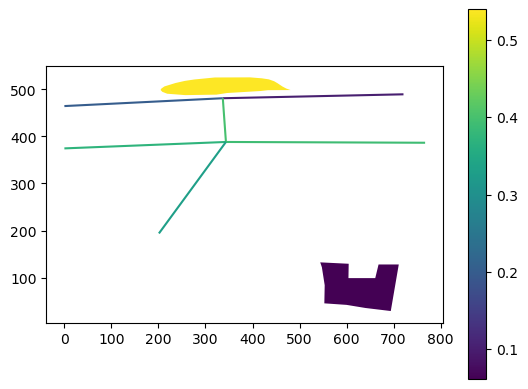

In [26]:
gdf.plot(column="Scale", legend=True)

<Axes: >

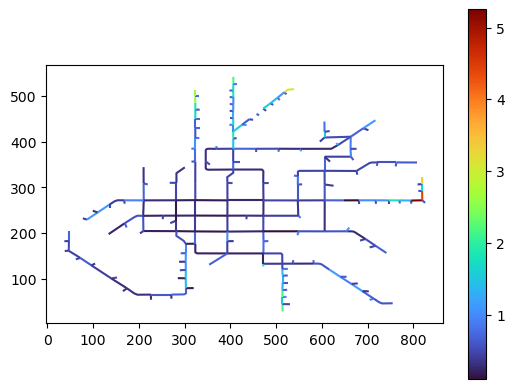

In [46]:
gdf_osaka.plot(column="Scale", legend=True, cmap="turbo")

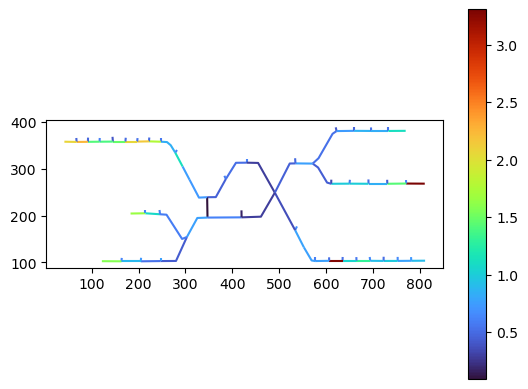

In [80]:
gdf_nuremberg.plot(column="Scale", legend=True, cmap="turbo")
plt.savefig('Visualisierungen\\1\\schematic\\nürnberg_vis1.png')

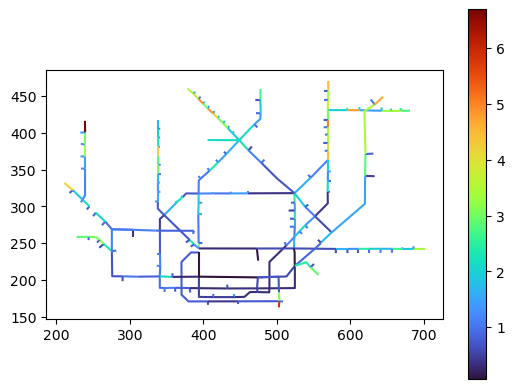

In [70]:
gdf_hamburg.plot(column="Scale", legend=True, cmap="turbo")
plt.savefig('hamburg_vis1.png')

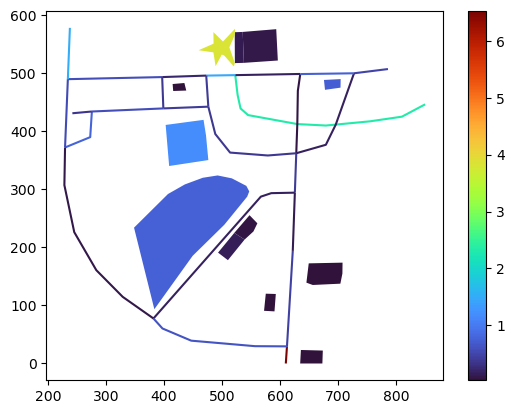

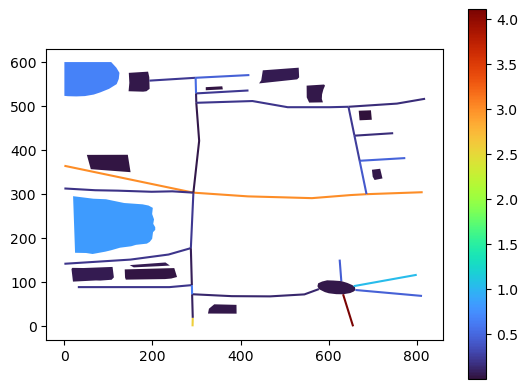

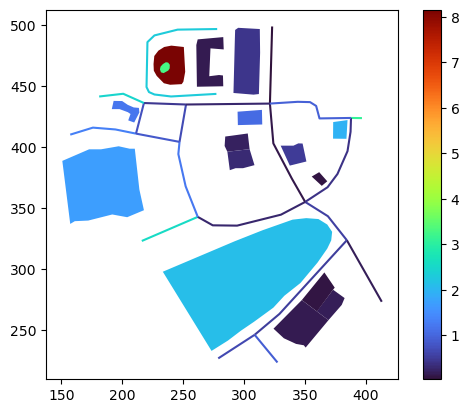

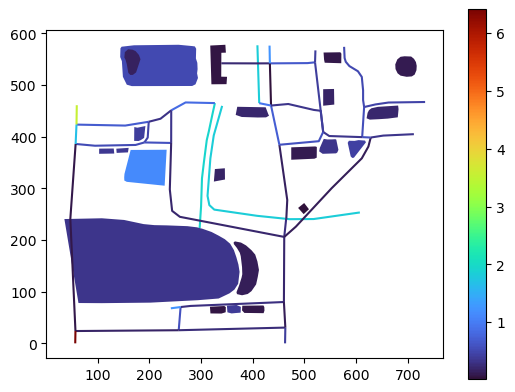

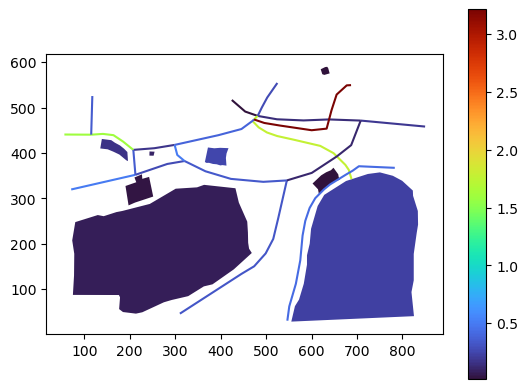

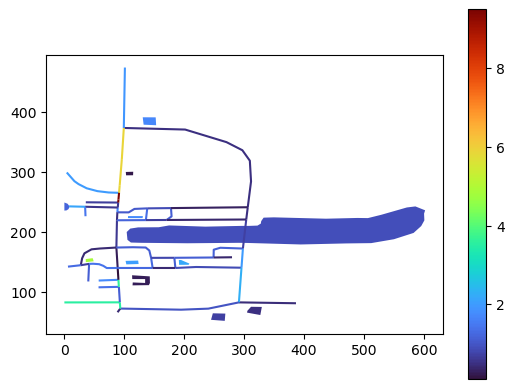

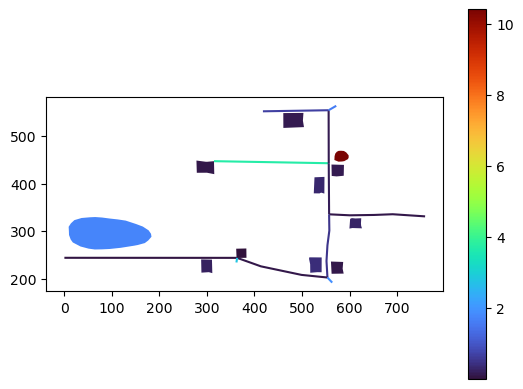

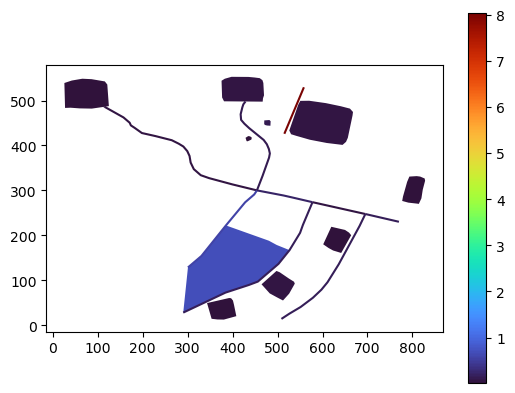

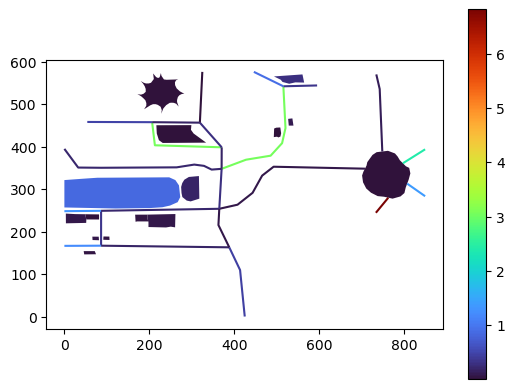

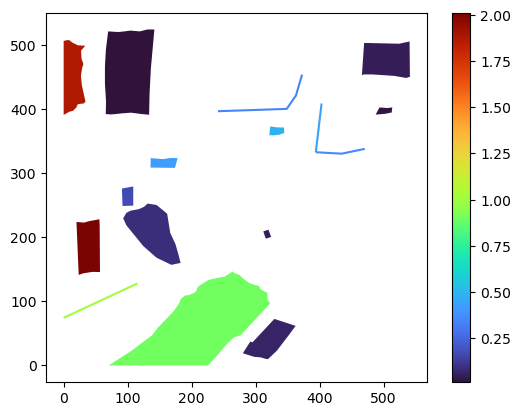

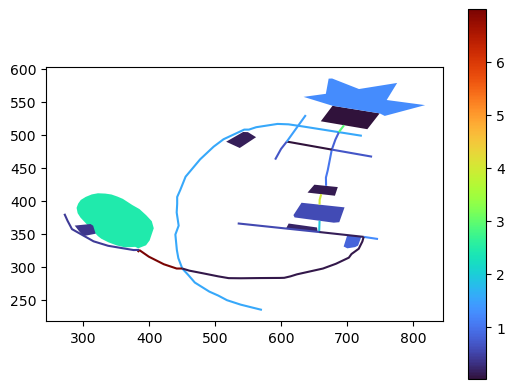

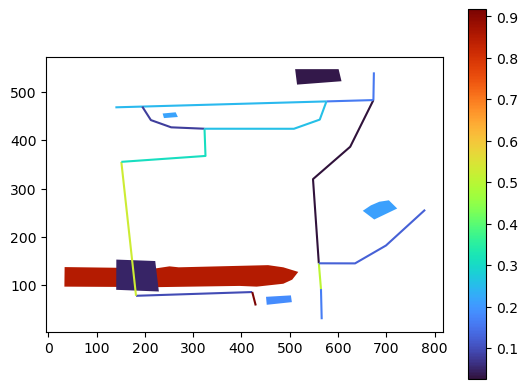

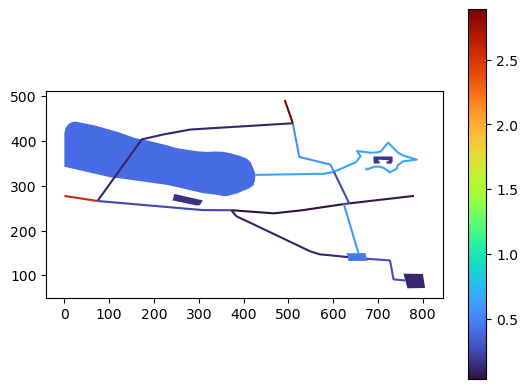

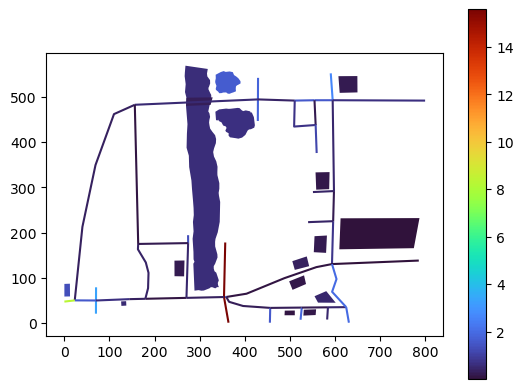

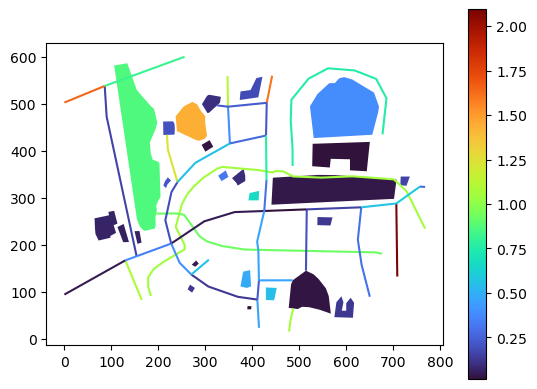

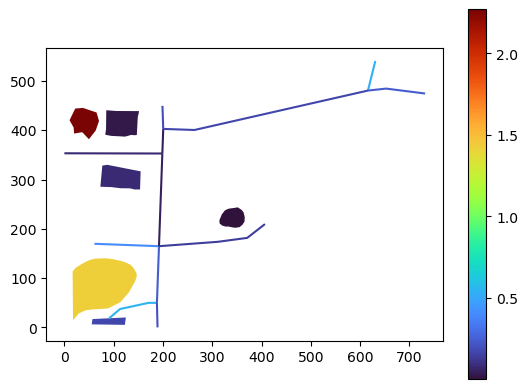

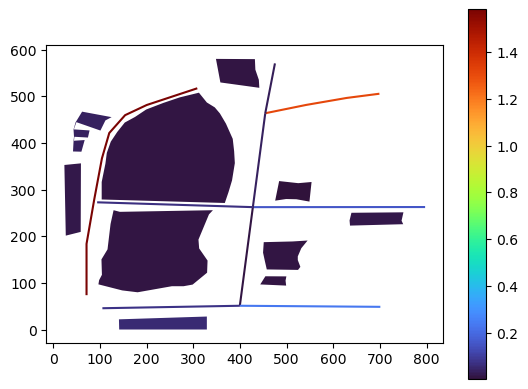

In [76]:
for sketchmap in gdf_ma_list:
    sketchmap.plot(column="Scale", legend=True, cmap="turbo")
    plt.savefig('Visualisierungen\\1\\sketch\\Route_MensaAasee\\' + sketchmap['Map_name'][0])

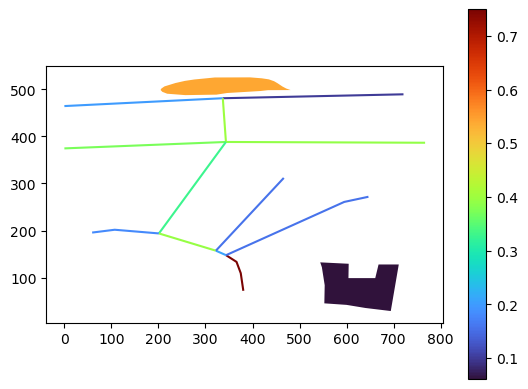

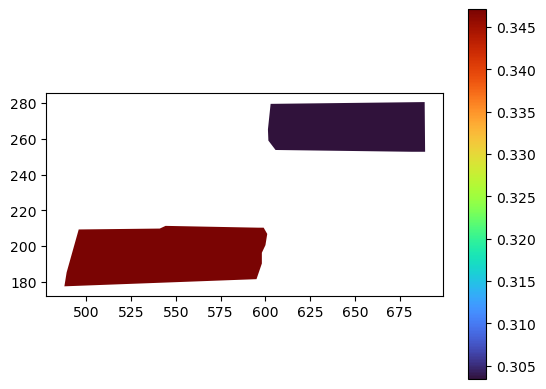

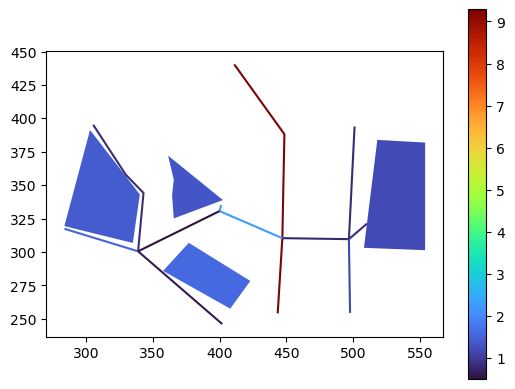

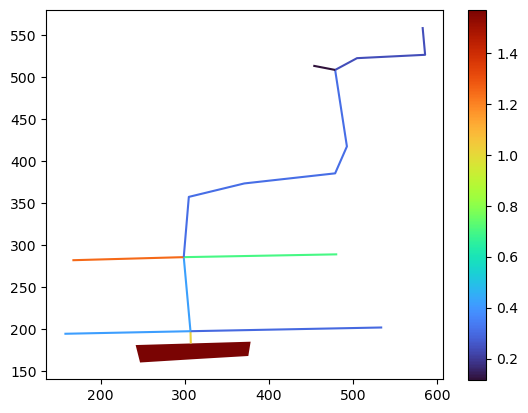

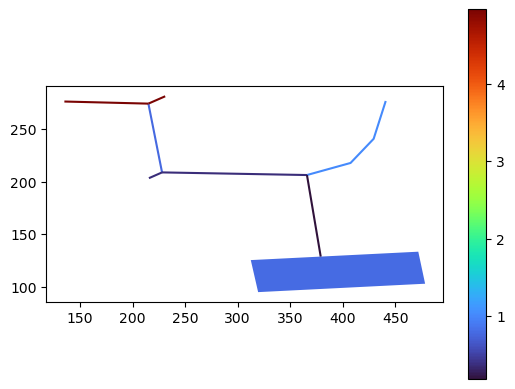

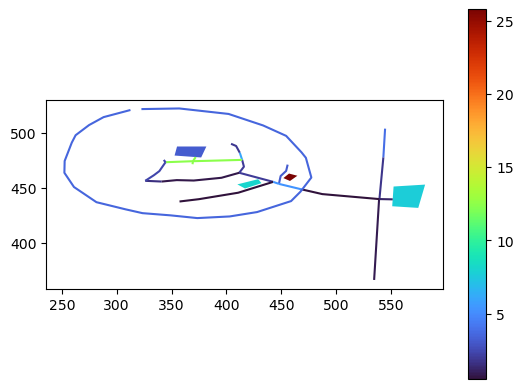

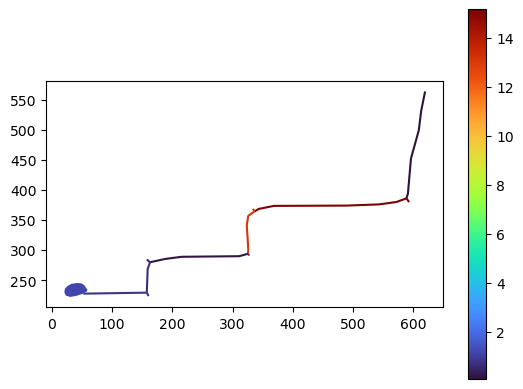

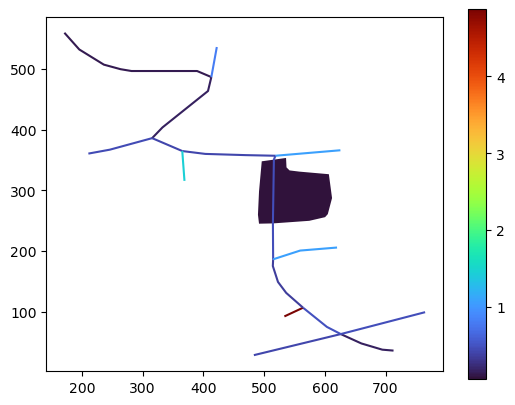

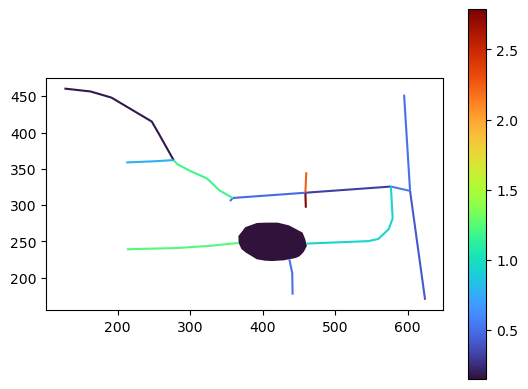

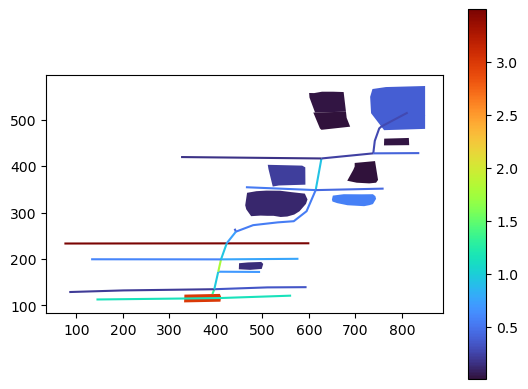

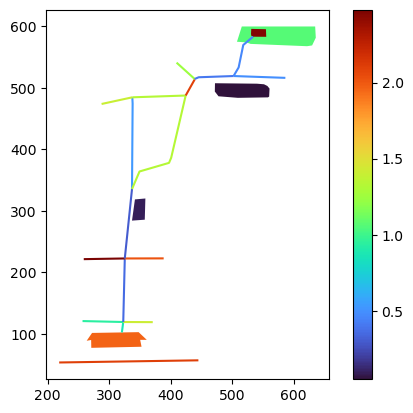

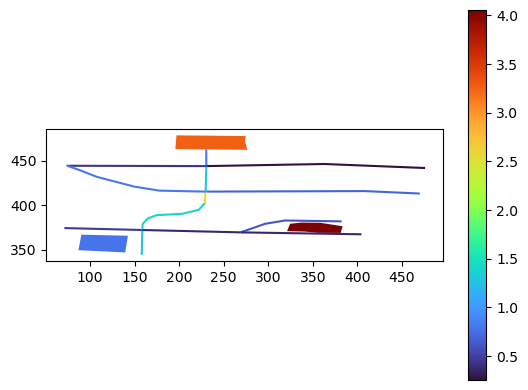

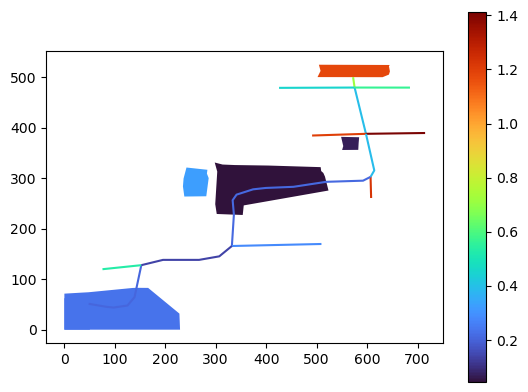

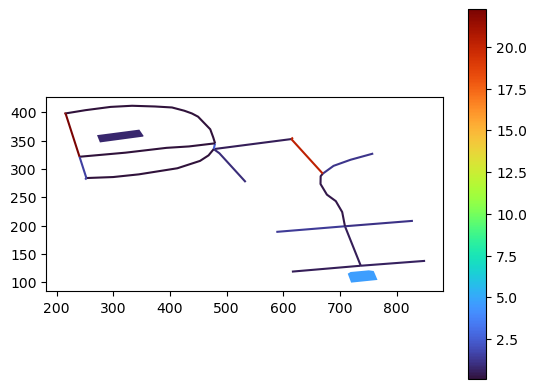

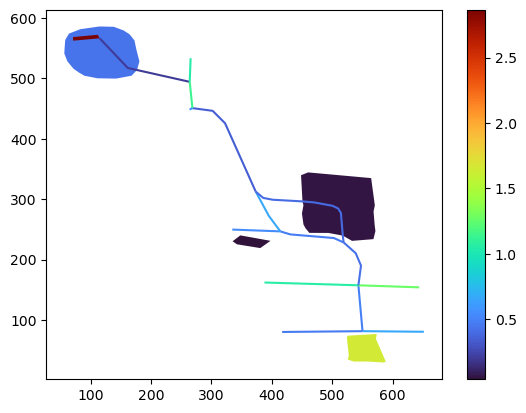

In [77]:
for sketchmap in gdf_hbfdom_list:
    sketchmap.plot(column="Scale", legend=True, cmap="turbo")
    plt.savefig('Visualisierungen\\1\\sketch\\Route_HbfDom\\' + sketchmap['Map_name'][0])

In [28]:
print(gdf_osaka['Scale'].max(), gdf_osaka['Scale'].min())

5.25292491347067 0.10747036162612289


In [81]:
gdf_nuremberg.to_file("Shapefiles\schematic\gdf_nuremberg.shp")

<>:1: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:1: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
C:\Users\Admin\AppData\Local\Temp\ipykernel_25152\1273597098.py:1: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
  gdf_nuremberg.to_file("Shapefiles\schematic\gdf_nuremberg.shp")
C:\Users\Admin\AppData\Local\Temp\ipykernel_25152\1273597098.py:1: UserWarning: Column names longer than 10 characters will be truncated when saved to ESRI Shapefile.
  gdf_nuremberg.to_file("Shapefiles\schematic\gdf_nuremberg.shp")
C:\Users\Admin\anaconda3\envs\sql\Lib\site-packages\pyogrio\geopandas.py:710: UserWarning: 'crs' was not provided.  The output dataset will not have projection information defined a

### No. 2
With QGIS

### No. 3: Isolines
With QGIS

### No. 4: Size differences

In [ ]:
# find minimal scale of sketch map
# bring all other elements to that scale: 
# 
# with gpd.GeoSeries.scale

### No. 5: Tissots indikatrix